# Time series of the global mean TOA energy balance

Global mean net downward energy flux at the top of the atmosphere (TOA) in the HD 209458b
simulations, from the output regridded by XIOS to a regular longitude-latitude grid
(`lfric_diag_latlon*.nc`, instantaneous fields written every 10 days).

The net flux is computed by `aeolus.calc.toa_net_energy()` as
$F_{net} = F_{SW,\downarrow} - F_{SW,\uparrow} - F_{LW,\uparrow}$
(`sw_direct_toa - sw_up_toa - lw_up_toa`), and averaged over the globe with area weights
by `aeolus.calc.spatial_mean()`.
The right-hand axis shows the imbalance relative to the global mean incoming stellar flux
(constant in time and the same in all experiments).

In equilibrium, the net downward flux at the TOA balances the internal heat flux
from the bottom boundary, i.e. $F_{net} \to -F_{int}$.

In [ ]:
import warnings

import iris
import matplotlib.pyplot as plt
import numpy as np
import paths
import seaborn as sns
from aeolus.calc import spatial_mean, toa_net_energy
from aeolus.model import lfric
from aeolus.plot import figsave
from common import (
    ALL_HD209_EXPERIMENTS,
    GROUPS,
    KW_REF_LINE,
    TIME_ORIGIN,
    load_exp_days,
)

warnings.filterwarnings("ignore")
iris.FUTURE.date_microseconds = True

print(*ALL_HD209_EXPERIMENTS.keys(), sep="\n")

hd209_dt30_nrad3
hd209_dt30_nrad4
hd209_dt30_nrad5
hd209_rand_t100k_nf20_tau1e5_amp1e-2_sclht6
hd209_ctrl


## Parameters

In [ ]:
# Experiments to plot
EXP_KEYS = ["hd209_ctrl"]  # GROUPS["hd209_all"].simulations
# Length of the period at the end of each run over which to print the mean balance (days)
N_DAYS_MEAN = 200
# (bottom, top) of the net TOA flux axis in W m-2, e.g. (-100, 5000); None for auto
YLIM = [0, 12_000]
SAVE_FIGS = True

## Load the data and calculate the global mean TOA balance

In [6]:
def global_mean_toa_balance(exp_key):
    """
    Time series of the global mean net downward TOA energy flux of one experiment,
    and of the global mean incoming stellar flux.
    """
    exp = ALL_HD209_EXPERIMENTS[exp_key]
    ds = load_exp_days(exp_key, 0, exp.run_length, experiments=ALL_HD209_EXPERIMENTS)
    net = spatial_mean(toa_net_energy(ds, model=lfric), model=lfric)
    isr = spatial_mean(ds.extract_cube(lfric.toa_isr), model=lfric)
    for cube in (net, isr):
        # Express time in days since the start of the run
        cube.coord("time").convert_units(f"days since {TIME_ORIGIN}")
    return net, isr


toa_net = {}
toa_isr = {}
for exp_key in EXP_KEYS:
    toa_net[exp_key], toa_isr[exp_key] = global_mean_toa_balance(exp_key)
    print(f"{exp_key}: {toa_net[exp_key].shape[0]} time steps")

hd209_ctrl: 120 time steps


In [7]:
print(f"Global mean TOA fluxes, mean over the last {N_DAYS_MEAN} days [W m-2]")
for exp_key, cube in toa_net.items():
    days = cube.coord("time").points
    in_period = days > days.max() - N_DAYS_MEAN
    net = cube.data[in_period]
    isr = toa_isr[exp_key].data[in_period]
    exp = ALL_HD209_EXPERIMENTS[exp_key]
    f_int = exp.internal_flux.value if exp.internal_flux is not None else np.nan
    print(
        f"{exp_key:>45}: net = {net.mean():9.2f} (std {net.std():7.2f})"
        f" | net / ISR = {100 * net.mean() / isr.mean():6.3f} %"
        f" | ISR = {isr.mean():.1f} | -F_int = {-f_int:.2f}"
    )

Global mean TOA fluxes, mean over the last 200 days [W m-2]
                                   hd209_ctrl: net =   3625.40 (std  212.86) | net / ISR =  1.590 % | ISR = 227978.2 | -F_int = -5.67


## Plot

Saved to ../figures/drafts/toa_balance/hd209_ctrl__toa_net_ts__latlon.pdf
Size: 21.4 KB


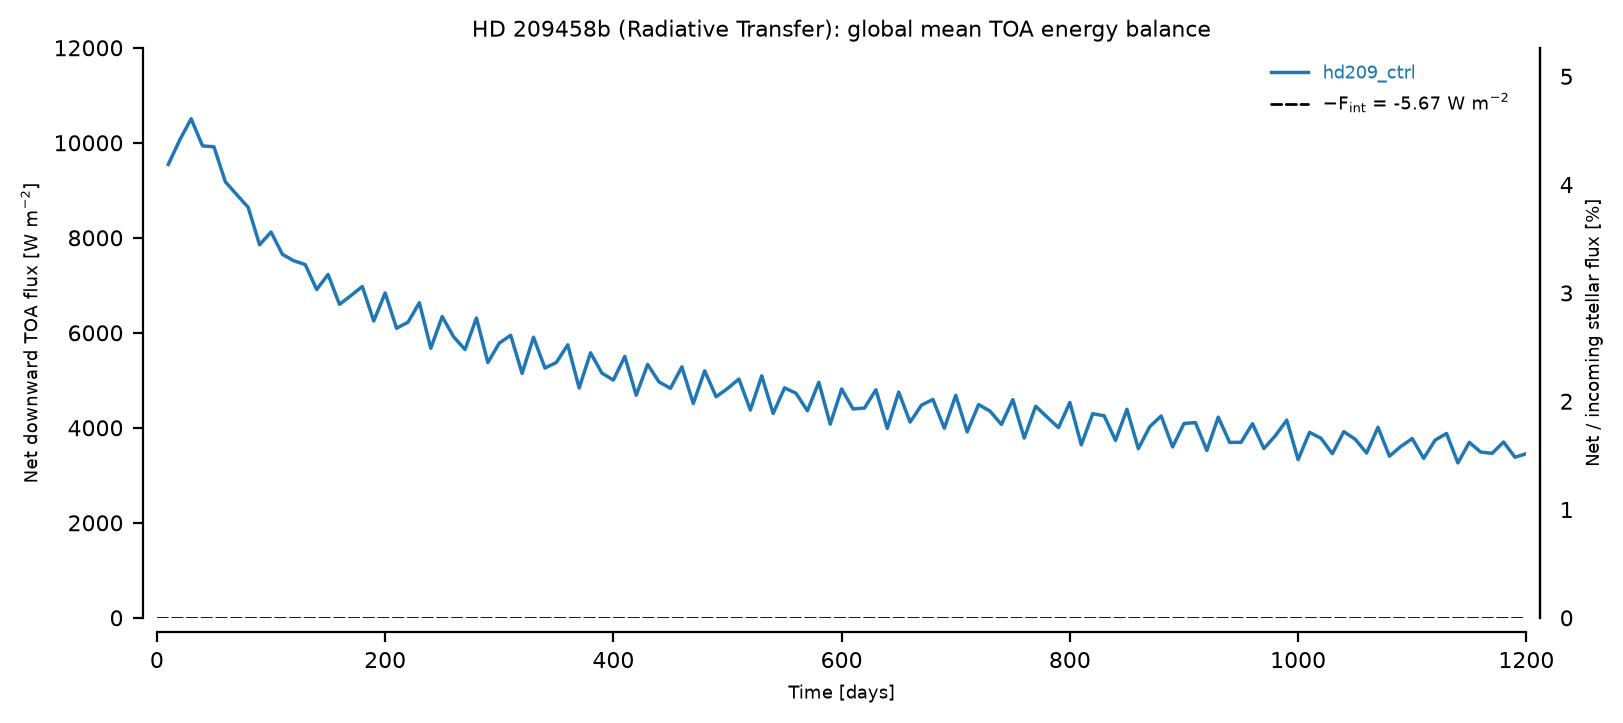

In [ ]:
def plot_toa_balance(toa_net, toa_isr, ylim=None, ylim2=None):
    """Plot the time series; `ylim` is (bottom, top) of the net flux axis in W m-2."""
    # The incoming stellar flux is fixed, so the relative imbalance is a linear
    # rescaling of the net flux and can be shown on a secondary axis
    isr = np.concatenate([cube.data for cube in toa_isr.values()])
    assert np.allclose(isr, isr.mean(), rtol=1e-6), "Incoming stellar flux varies"
    isr = isr.mean()

    fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
    for i, (exp_key, net) in enumerate(toa_net.items()):
        ax.plot(
            net.coord("time").points, net.data, color=f"C{i}", lw=1.25, label=exp_key
        )
    # Equilibrium value: the net TOA flux balances the internal heat flux
    f_int = {
        ALL_HD209_EXPERIMENTS[k].internal_flux.value
        for k in toa_net
        if ALL_HD209_EXPERIMENTS[k].internal_flux is not None
    }
    for val in f_int:
        ax.axhline(
            -val, **KW_REF_LINE, label=rf"$-F_{{int}}$ = {-val:.2f} W m$^{{-2}}$"
        )
    secax = ax.secondary_yaxis(
        "right", functions=(lambda x: 100 * x / isr, lambda y: y * isr / 100)
    )
    secax.set_ylabel("Net / incoming stellar flux [%]")
    if ylim2 is not None:
        secax.set_ylim(ylim2)
    ax.set_ylabel("Net downward TOA flux [W m$^{-2}$]")
    ax.set_xlabel("Time [days]")
    ax.set_xlim(0, max(c.coord("time").points.max() for c in toa_net.values()))
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_title(
        f"{GROUPS['hd209_all'].title}: global mean TOA energy balance", size="medium"
    )
    ax.legend(loc="upper right", fontsize="small", frameon=False)
    sns.despine(ax=ax, offset=5, right=False)
    sns.despine(ax=secax, offset=5, left=True, right=False)
    if SAVE_FIGS:
        figsave(
            fig,
            paths.drafts
            / "toa_balance"
            / f"{'_'.join(toa_net.keys())}__toa_net_ts__latlon",
        )
    return fig


plot_toa_balance(toa_net, toa_isr, ylim=YLIM);